# Machine-learned noise selection and noise PSD templates (local and global)

**Project.** The optimal filter (OF) needs a *noise template*: the power spectral density $J(f)$ of the detector noise, estimated from traces that hold **only** noise. The current method chooses those traces with hand-tuned cuts on a single channel (a quiet pretrigger, `log10(bstd)`, and a band in the excursion ratio; see `student/buddy/psd-clean-randoms-buddy.ipynb` and Notes 2 and 2a). Hand cuts throw away good traces (the threshold is a percentile, so a fixed share is lost by construction) and they let through some traces with small pulses or tails, which raise the low-frequency end of the PSD.

This notebook:

1. loads one dump and builds **time-domain and frequency-domain features** for every trace of every working channel;
2. trains a **machine-learning classifier** of good and bad noise traces. There are no hand labels, so it is *semi-supervised*: confident seeds from conservative cuts, plus **simulated bad traces** (real pulses, spikes and drifts injected into good noise traces), whose truth is known;
3. **measures** how well each method classifies (the current cut, an unsupervised Isolation Forest as in `legacy/MLmodelImplementaion.ipynb`, and the new classifier): the share of clean traces kept, and the share of injected pulses rejected as a function of their size;
4. builds the **noise PSD template** from every trace the classifier accepts and compares it with the current method's template, including the optimal-filter resolution each one gives on traces it has not seen;
5. builds **local templates** (blocks of the dump, and a rolling template around each event) and tests whether they hold information the dump-wide template misses;
6. saves the templates to HDF5.

**Conventions** (same as the library and buddy's notebook): one-sided PSD $S(f) = \frac{2\,\Delta t}{N}|X_k|^2$ in counts²/Hz, no factor 2 at DC and Nyquist, baseline-subtracted (pretrigger mean) and with the 10 glitch samples dropped. Golwala's thesis (the *Optimal Filter Reference* in `legacy/`) writes the two-sided $J = S/2$; the OF resolution below is computed consistently with $S$.

**What to keep in mind about this dump** (checked in section 1):

- It is series `07180827_0000`, dump `F0002`, the dump used by `Fourier Transform Analysis.ipynb` and `MLmodelImplementaion.ipynb`. It is **not** the Run 76 Side-2 series of the library's channel map, so channels are named by their dump index `(detector, channel)`, not by sensor name.
- **The sample period is an assumption**: 0.8 µs (1.25 MHz), as in `Fourier Transform Analysis.ipynb` and the library's `DCRC_RUN76`. If this 2018 series used another readout, every frequency scales (and the PSD with it); nothing counted in samples changes. Change `SAMPLE_PERIOD_S` below if you find the right value.
- Every event in this dump has trigger type `Unknown`, so the random-trigger label of the current method (`cuts.randoms`) cannot be used; all traces are candidates. Worse, the dump seems to hold **no random triggers at all**: about half the events have a large pulse, and many of the rest have a small pulse at the trigger time (section 2.3). Noise traces from a dump of triggers are never as clean as random triggers, and section 4 measures how much each method lets in.

In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import h5py
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from nsdf_dark_matter.idx import load_all_data

from goldpan import quantities as q, cuts, operations as op, io
from goldpan.config import PulseConfig
import check_environment
check_environment.check()

DUMP = "07180827_0000_F0002"
SAMPLE_PERIOD_S = 0.8e-6          # ASSUMED (see the introduction)
PRETRIGGER = 500                  # the trigger is at sample ~517 (section 1)
CONFIG = PulseConfig(pretrigger_samples=PRETRIGGER, glitch_samples=10, sample_period_s=SAMPLE_PERIOD_S)
# The traces below are stored baseline-subtracted with the glitch samples already dropped, so the library
# functions see them through this config: the pretrigger is 490 samples and nothing more is skipped.
CONFIG_P = PulseConfig(pretrigger_samples=PRETRIGGER - CONFIG.glitch_samples, glitch_samples=0, sample_period_s=SAMPLE_PERIOD_S)

RNG = np.random.default_rng(76)
# one colour per method, used in every figure
COLOUR = {"current cut": "#eb6834", "ML classifier": "#2a78d6", "Isolation Forest": "#1baf7a", "seed good": "#52514e"}
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", ["#2a78d6", "#f0efec", "#eb6834"])
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

Environment OK: Python 3.12.16, and the 13 packages in requirements.txt match.


## 1. Load the dump

Each event has detectors 0 and 2, four channels each, 4096 samples (a handful of events also list detectors 4 and 6; those are left out, since only detectors present in every event are used). All traces are read once into memory (as `float32`, baseline-subtracted, glitch samples dropped: about 750 MB for the six working channels). A channel that is not read out (`cuts.dead_channel`: zero pretrigger scatter) in most events is *dead* and is left out; detector 0 channel 3 has a signal in only one event.

In [2]:
t0 = time.time()
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
all_ids = cdms.get_detector_ids()
counts = {}
for i in all_ids:
    counts[io.detector_index(i)] = counts.get(io.detector_index(i), 0) + 1
n_ev_max = max(counts.values())
detectors = sorted(d for d, c in counts.items() if c == n_ev_max)       # detectors present in every event
print("events per detector index:", counts, "-> using", detectors)
det_ids = {det: io.filter_by_detector(all_ids, det) for det in detectors}

# every detector must list the same events in the same order
event_numbers = np.array([int(io.event_id(i)) for i in det_ids[detectors[0]]])
for det in detectors[1:]:
    assert np.array_equal(event_numbers, [int(io.event_id(i)) for i in det_ids[det]])
n_events = len(event_numbers)

# global timestamps (1 s resolution) from the dump's .csv
csv = np.genfromtxt(Path.home() / "idx" / DUMP / f"{DUMP}.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
ts_by_event = dict(zip(csv["event"], csv["global_timestamp"]))
timestamps = np.array([ts_by_event[e] for e in event_numbers]) - min(ts_by_event.values())
print("trigger types in the .csv:", dict(zip(*np.unique(csv["trigger_type"], return_counts=True))))

raw_traces = {}      # (det, ch) -> processed traces, float32, shape (events, 4086)
dead = []
for det in detectors:
    block = np.stack([cdms.get_detector_channels(i) for i in det_ids[det]]).astype(np.float32)   # (events, 4, 4096); raw is uint16
    for ch in range(block.shape[1]):
        x = block[:, ch, :]
        if cuts.dead_channel(x, CONFIG).mean() > 0.5:         # not read out in most events
            dead.append((det, ch))
            continue
        raw_traces[(det, ch)] = op.trim_glitch(op.baseline_subtract(x, CONFIG), CONFIG).astype(np.float32)
    del block
KEYS = list(raw_traces)
N_SAMP = raw_traces[KEYS[0]].shape[1]
print(f"{n_events} events over {timestamps.max()} s, working channels {KEYS}, dead {dead}")
print(f"{N_SAMP} samples per trace after the glitch, loaded in {time.time() - t0:.0f} s")

events per detector index: {0: 7588, 2: 7588, 4: 4, 6: 4} -> using [0, 2]
trigger types in the .csv: {np.str_('Unknown'): np.int64(7588)}
7588 events over 62 s, working channels [(0, 0), (0, 1), (0, 2), (2, 1), (2, 2), (2, 3)], dead [(0, 3), (2, 0)]
4086 samples per trace after the glitch, loaded in 4 s


### 1.1 What the traces look like

About half the traces carry a large pulse (thousands of counts) and the other half look like noise (a few counts). The trigger sample comes from the large pulses: the median sample where they first pass 20% of their peak.

(0, 0): 3571 of 7588 traces have a peak above 1000 counts; median onset sample of those 517 (the 10 glitch samples counted)


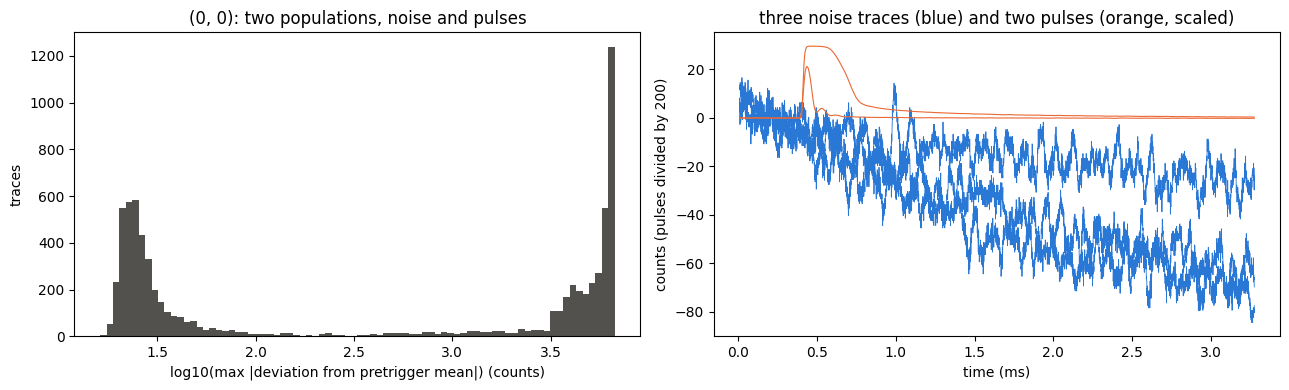

In [3]:
key0 = KEYS[0]
x = raw_traces[key0]
maxdev = np.abs(x).max(axis=1)
big = maxdev > 1000
onset = np.argmax(np.abs(x[big]) > 0.2 * maxdev[big, None], axis=1) + CONFIG.glitch_samples   # in raw samples
print(f"{key0}: {big.sum()} of {n_events} traces have a peak above 1000 counts; "
      f"median onset sample of those {np.median(onset):.0f} (the 10 glitch samples counted)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(maxdev), bins=80, color="#52514e")
axes[0].set_xlabel("log10(max |deviation from pretrigger mean|) (counts)"); axes[0].set_ylabel("traces")
axes[0].set_title(f"{key0}: two populations, noise and pulses")
t_ms = (np.arange(N_SAMP) + CONFIG.glitch_samples) * SAMPLE_PERIOD_S * 1e3
quiet_i = np.flatnonzero(~big)[:3]; big_i = np.flatnonzero(big)[:2]
for i in quiet_i:
    axes[1].plot(t_ms, x[i], lw=0.6, color="#2a78d6")
for i in big_i:
    axes[1].plot(t_ms, x[i] / 200, lw=0.8, color="#eb6834")
axes[1].set_xlabel("time (ms)"); axes[1].set_ylabel("counts (pulses divided by 200)")
axes[1].set_title("three noise traces (blue) and two pulses (orange, scaled)")
fig.tight_layout(); plt.show()

## 2. Features of every trace

Each trace is described by numbers that a person would look at, so that the classifier's choices can be checked by eye.

**Time domain** (σ is the pretrigger standard deviation, `bstd`):

| feature | catches |
|---|---|
| `log_bstd`, `log_std_post` | a noisy or contaminated pretrigger; a pulse after the trigger |
| `log_maxdev_pre`, `log_maxdev_post` | the largest excursion before and after the trigger (library: `max_deviation`) |
| `log_ratio` | `log_excursion_ratio`, the quantity of the current cut |
| `smooth_peak` | the largest excursion of a 50-sample running mean, in units of σ/√50: small slow pulses that hide in the sample-to-sample noise |
| `drift`, `slope` | the end of the trace minus the start, and a straight-line slope, in units of σ: tails of earlier pulses |
| `spike` | the largest sample-to-sample jump over its own scatter: glitches |
| `skew`, `kurt` | asymmetry and heavy tails of the sample distribution |

**Frequency domain** (per-trace one-sided PSD, compared with the channel's median PSD, which is robust to the half of traces that hold pulses):

| feature | catches |
|---|---|
| `band_k` (8 log-spaced bands, 300 Hz to 625 kHz) | log10 of the trace's power over the median power in each band: pulses and tails put power at low frequency |
| `psd_peak` | the largest single-bin excess: a line or a burst at one frequency |
| `psd_mean_log` | the mean log excess over all bins (an overall noise level) |

**Optimal filter**: `of_trig` and `of_peak` (section 2.2).

**Across channels**: `other_smooth`, `other_maxdev` and `other_of`, the largest `smooth_peak`, `log_maxdev_post` and `of_peak` in the other working channels of the same event. A real pulse shows up in several channels at once.

Before going into the classifier the features are put on a common scale (section 2.3).

In [4]:
BAND_EDGES = np.geomspace(300, 1 / (2 * SAMPLE_PERIOD_S), 9)
FREQS = q.frequencies_hz(N_SAMP, CONFIG_P)
BAND_BINS = [(FREQS >= lo) & (FREQS < hi) for lo, hi in zip(BAND_EDGES[:-1], BAND_EDGES[1:])]
TIME_FEATURES = ["log_bstd", "log_std_post", "log_maxdev_pre", "log_maxdev_post", "log_ratio",
                 "smooth_peak", "drift", "slope", "spike", "skew", "kurt"]
FREQ_FEATURES = [f"band_{k}" for k in range(len(BAND_BINS))] + ["psd_peak", "psd_mean_log"]
OF_FEATURES = ["of_peak", "of_trig"]
CROSS_FEATURES = ["other_smooth", "other_maxdev", "other_of"]
FEATURES = TIME_FEATURES + FREQ_FEATURES + OF_FEATURES + CROSS_FEATURES
KBINS = slice(1, len(FREQS) - 1)        # positive frequencies without DC and Nyquist


def one_sided_psd(traces):
    # One-sided PSD (counts^2/Hz) of each trace: (2 dt / N) |X_k|^2, without the factor 2 at DC and Nyquist.
    n = traces.shape[-1]
    psd = q.power_spectrum(traces, CONFIG_P) * (SAMPLE_PERIOD_S / n)
    psd[..., 1:(n + 1) // 2 if n % 2 else n // 2] *= 2
    return psd


def channel_features(x, ref_psd=None, chunk=1000):
    # Time- and frequency-domain features of a batch of processed traces (events, samples), as a dict of arrays.
    # ref_psd: the channel's median PSD; computed from this batch if not given (pass it for injected traces).
    pre = x[:, :CONFIG_P.pretrigger_samples]
    post = x[:, CONFIG_P.pretrigger_samples:]
    bstd = np.maximum(pre.std(axis=1), 1e-3)
    f = {}
    f["log_bstd"] = np.log10(bstd)
    f["log_std_post"] = np.log10(np.maximum(post.std(axis=1), 1e-3))
    f["log_maxdev_pre"] = np.log10(np.abs(pre).max(axis=1) + 1e-3)
    f["log_maxdev_post"] = np.log10(q.max_deviation(x, CONFIG_P) + 1e-3)
    f["log_ratio"] = np.log10(q.max_deviation(x, CONFIG_P) / bstd + 1e-6)
    w = 50
    c = np.cumsum(np.pad(x, ((0, 0), (1, 0))), axis=1, dtype=np.float64)
    smooth = (c[:, w:] - c[:, :-w]) / w
    f["smooth_peak"] = np.abs(smooth).max(axis=1) / (bstd / np.sqrt(w))
    f["drift"] = (x[:, -500:].mean(axis=1) - pre.mean(axis=1)) / bstd
    t = np.arange(x.shape[1]) - (x.shape[1] - 1) / 2
    f["slope"] = (x @ t) / (t @ t) * x.shape[1] / bstd
    d = np.diff(x, axis=1)
    f["spike"] = np.abs(d).max(axis=1) / np.maximum(d.std(axis=1), 1e-3)
    z = (x - x.mean(axis=1, keepdims=True)) / np.maximum(x.std(axis=1, keepdims=True), 1e-3)
    f["skew"] = (z ** 3).mean(axis=1)
    f["kurt"] = (z ** 4).mean(axis=1) - 3
    psd = np.concatenate([one_sided_psd(x[i:i + chunk]) for i in range(0, len(x), chunk)])
    if ref_psd is None:
        ref_psd = np.median(psd, axis=0)
    rel = np.maximum(psd[:, 1:-1] / ref_psd[1:-1], 1e-12)
    for k, b in enumerate(BAND_BINS):
        f[f"band_{k}"] = np.log10(psd[:, b].mean(axis=1) / ref_psd[b].mean())
    f["psd_peak"] = np.log10(rel.max(axis=1))
    f["psd_mean_log"] = np.log(rel).mean(axis=1)
    return f, ref_psd


def add_cross_features(feats):
    # feats: {key: dict of arrays over the same events}. Adds the largest value in the other channels.
    for key in feats:
        others = [k for k in feats if k != key]
        feats[key]["other_smooth"] = np.max([feats[k]["smooth_peak"] for k in others], axis=0)
        feats[key]["other_maxdev"] = np.max([feats[k]["log_maxdev_post"] for k in others], axis=0)
        feats[key]["other_of"] = np.max([feats[k]["of_peak"] for k in others], axis=0)
    return feats


t0 = time.time()
feats, REF_PSD, NOISE_SIGMA = {}, {}, {}
for key in KEYS:
    feats[key], REF_PSD[key] = channel_features(raw_traces[key])
    bstd = 10 ** feats[key]["log_bstd"]
    NOISE_SIGMA[key] = np.median(bstd[bstd < 3 * np.percentile(bstd, 10)])      # typical noise of the channel
    print(f"{key}: typical noise sigma {NOISE_SIGMA[key]:.2f} counts")
print(f"time and frequency features of {len(KEYS)} x {n_events} traces in {time.time() - t0:.0f} s")

(0, 0): typical noise sigma 5.93 counts


(0, 1): typical noise sigma 5.63 counts


(0, 2): typical noise sigma 5.74 counts


(2, 1): typical noise sigma 4.44 counts


(2, 2): typical noise sigma 9.71 counts


(2, 3): typical noise sigma 7.89 counts
time and frequency features of 6 x 7588 traces in 21 s


### 2.1 The pulse shape of each channel

Averaged from large but unsaturated pulses (100 to 2000 counts) that start at the trigger (raw onset sample 500 to 540) on a quiet pretrigger. Each is divided by its peak before averaging, and the average is scaled to a peak of 1. The same shape is the signal template $s(t)$ of the optimal filter, here and in section 5.

(0, 0): pulse shape from 239 pulses
(0, 1): pulse shape from 293 pulses
(0, 2): pulse shape from 303 pulses
(2, 1): pulse shape from 509 pulses
(2, 2): pulse shape from 214 pulses
(2, 3): pulse shape from 216 pulses


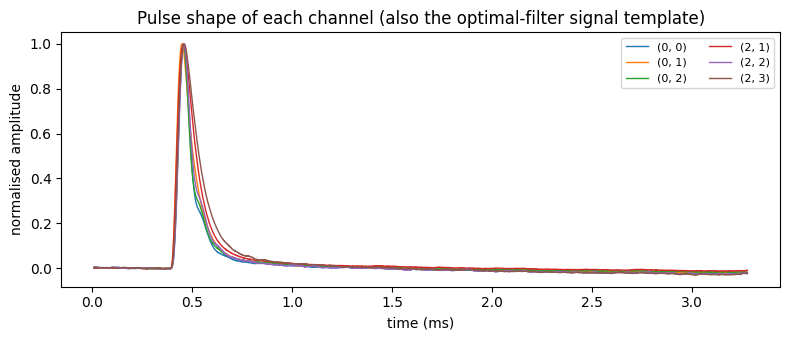

In [5]:
PULSE = {}
for key in KEYS:
    x = raw_traces[key]
    peak = x.max(axis=1)
    on = np.argmax(x > 0.2 * peak[:, None], axis=1) + CONFIG.glitch_samples
    ok = ((peak > 100) & (peak < 2000) & (on >= 500) & (on <= 540)
          & (10 ** feats[key]["log_bstd"] < 1.5 * NOISE_SIGMA[key]))
    shape = (x[ok] / peak[ok, None]).mean(axis=0)
    PULSE[key] = shape / shape.max()
    print(f"{key}: pulse shape from {ok.sum()} pulses")

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, key in enumerate(KEYS):
    ax.plot(t_ms, PULSE[key], lw=1, label=str(key))
ax.set_xlabel("time (ms)"); ax.set_ylabel("normalised amplitude"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Pulse shape of each channel (also the optimal-filter signal template)")
fig.tight_layout(); plt.show()

### 2.2 Optimal-filter features

The most sensitive detector of a small pulse of known shape in noise of known spectrum *is* the optimal filter. So the OF itself provides two features: the trace is filtered with the pulse shape and a **preliminary** noise PSD (the mean of a small, very strict set of quiet traces), giving the fitted amplitude $\hat A(\tau)$ for every start time $\tau$ (section 5 has the formula; here as a circular cross-correlation, all shifts at once with one FFT).

| feature | catches |
|---|---|
| `of_trig` | $\hat A$ at the trigger time, in units of its expected noise spread $\sigma_A$ (signed) |
| `of_peak` | the largest $|\hat A(\tau)|/\sigma_A$ over all start times: a small pulse anywhere in the trace |

and `other_of`, the largest `of_peak` in the other channels of the event. For pure noise `of_peak` is about 3 to 4 (the largest of ~4000 correlated values).

In [6]:
def of_setup(key, J):
    # Frequency-domain OF weights for the pulse shape of `key` and noise PSD J; also the norm and sigma_A.
    S = np.fft.rfft(PULSE[key])
    W = np.zeros_like(S)
    W[KBINS] = np.conj(S[KBINS]) / J[KBINS]
    norm = np.sum(np.abs(S[KBINS]) ** 2 / J[KBINS])
    return W, norm, np.sqrt(N_SAMP / (4 * SAMPLE_PERIOD_S * norm))


def of_features(key, x, chunk=1000):
    # A(tau) for every start time: sum_k Re(W_k V_k e^{2 pi i k tau / N}) / norm = irfft(W V) * N/2 / norm
    W, norm, sigma = OF_SETUP[key]
    peak, trig = [], []
    for i in range(0, len(x), chunk):
        A = np.fft.irfft(np.fft.rfft(x[i:i + chunk], axis=1) * W, n=N_SAMP, axis=1) * (N_SAMP / 2) / norm
        peak.append(np.abs(A).max(axis=1) / sigma)
        trig.append(A[:, 0] / sigma)
    return {"of_peak": np.concatenate(peak), "of_trig": np.concatenate(trig)}


OF_SETUP, PRELIM_PSD = {}, {}
for key in KEYS:
    f = feats[key]
    bstd = 10 ** f["log_bstd"]
    quiet = bstd < 1.2 * NOISE_SIGMA[key]
    # a strict preliminary selection, only for the preliminary PSD: quiet, flat, no excursion, no slow bump
    strict = (quiet & (f["log_ratio"] < 0.65) & (np.abs(f["drift"]) < 2)
              & (f["smooth_peak"] < np.median(f["smooth_peak"][quiet])))
    J0 = one_sided_psd(raw_traces[key][strict]).mean(axis=0)
    PRELIM_PSD[key] = J0
    OF_SETUP[key] = of_setup(key, J0)
    feats[key].update(of_features(key, raw_traces[key]))
    print(f"{key}: preliminary PSD from {strict.sum()} strict traces, sigma_A = {OF_SETUP[key][2]:.2f} counts; "
          f"median of_peak {np.median(feats[key]['of_peak'][strict]):.2f} in them")
feats = add_cross_features(feats)
print(f"{len(FEATURES)} features in all")

(0, 0): preliminary PSD from 1713 strict traces, sigma_A = 4.08 counts; median of_peak 2.83 in them


(0, 1): preliminary PSD from 1627 strict traces, sigma_A = 3.72 counts; median of_peak 2.79 in them


(0, 2): preliminary PSD from 1908 strict traces, sigma_A = 3.14 counts; median of_peak 2.74 in them


(2, 1): preliminary PSD from 1802 strict traces, sigma_A = 2.49 counts; median of_peak 2.74 in them


(2, 2): preliminary PSD from 1604 strict traces, sigma_A = 8.24 counts; median of_peak 2.93 in them


(2, 3): preliminary PSD from 1411 strict traces, sigma_A = 5.84 counts; median of_peak 2.84 in them
26 features in all


### 2.3 A common scale for the features

Every feature is put on a common scale for each channel, so that a value of 5 means "5 spreads away from typical noise" in every channel and one model can be trained on all channels together. The median and spread (1.4826 × the median absolute deviation) come from:

- for the time- and frequency-domain features: the channel's *core*, the traces with σ below 1.5 times the channel's typical noise; for the cross-channel ones, the events that are in the core of every channel;
- for the OF features: **simulated pure Gaussian noise** with the preliminary PSD. The core cannot be used for them: it holds many small pulses at the trigger (next paragraph), and their median and spread would hide exactly what these features are for.

**Why the trigger matters here.** Every event in this dump is a *trigger* (there are no random triggers), so a trace that looks like noise is usually an event whose triggering pulse was small or in another channel. For pure noise `of_trig` is centred on 0 with a spread of 1; in the quiet core it is not (printed below). The simulation also checks the OF arithmetic: in simulated noise `of_trig` must have a spread of 1.

In [7]:
def simulate_noise(J, n, rng):
    # n traces of stationary Gaussian noise whose one-sided PSD is J: E|X_k|^2 = J_k N / (2 dt), random phases.
    amp = np.sqrt(J * N_SAMP / (2 * SAMPLE_PERIOD_S))
    X = (rng.standard_normal((n, len(J))) + 1j * rng.standard_normal((n, len(J)))) * amp / np.sqrt(2)
    X[:, 0] = 0; X[:, -1] = 0
    return np.fft.irfft(X, n=N_SAMP, axis=1).astype(np.float32)


rng_sim = np.random.default_rng(1)
SIM_OF = {key: of_features(key, simulate_noise(PRELIM_PSD[key], 4000, rng_sim)) for key in KEYS}
for key in KEYS:
    SIM_OF[key]["other_of"] = np.max([SIM_OF[k]["of_peak"] for k in KEYS if k != key], axis=0)


def robust(v):
    med = np.median(v)
    mad = 1.4826 * np.median(np.abs(v - med))
    return med, (mad if mad > 0 else 1.0)


all_core = np.all([10 ** feats[k]["log_bstd"] < 1.5 * NOISE_SIGMA[k] for k in KEYS], axis=0)
SCALE = {}
print(f"{'channel':<9}{'core':>6}{'sim of_trig mean, std':>24}{'sim of_peak median':>20}{'core of_trig mean':>19}{'core share of_trig > 3':>24}")
for key in KEYS:
    core = 10 ** feats[key]["log_bstd"] < 1.5 * NOISE_SIGMA[key]
    SCALE[key] = {}
    for name in FEATURES:
        if name in OF_FEATURES or name == "other_of":
            SCALE[key][name] = robust(SIM_OF[key][name])
        elif name.startswith("other"):
            SCALE[key][name] = robust(feats[key][name][all_core])
        else:
            SCALE[key][name] = robust(feats[key][name][core])
    st = SIM_OF[key]["of_trig"]; ct = feats[key]["of_trig"][core]
    print(f"{str(key):<9}{core.sum():>6}{st.mean():>12.2f}, {st.std():<11.2f}{np.median(SIM_OF[key]['of_peak']):>20.2f}"
          f"{ct.mean():>19.2f}{(ct > 3).mean():>24.1%}")


def scaled_matrix(key, f):
    X = np.column_stack([(f[n] - SCALE[key][n][0]) / SCALE[key][n][1] for n in FEATURES])
    return np.clip(np.nan_to_num(X, nan=0.0), -1e4, 1e4)     # a dead trace in one event must not break the fit


X_all = {key: scaled_matrix(key, feats[key]) for key in KEYS}

channel    core   sim of_trig mean, std  sim of_peak median  core of_trig mean  core share of_trig > 3
(0, 0)     6151        0.01, 1.01                       2.82             331.39                   33.1%
(0, 1)     6380        0.01, 1.01                       2.79             367.26                   33.6%
(0, 2)     6195        0.01, 1.00                       2.75             364.06                   30.9%
(2, 1)     6538        0.00, 0.99                       2.74             339.62                   33.6%
(2, 2)     6286        0.03, 1.02                       2.95             247.39                   38.9%
(2, 3)     6386       -0.01, 1.00                       2.82             311.79                   40.3%


## 3. Labels: confident seeds and simulated bad traces

**Seeds.** A trace is a *seed good* if every time-domain feature, both OF features and the cross-channel features are within 3 spreads of typical noise; it is a *seed bad* if it is obviously not noise (an excursion, a running-mean peak or an OF peak more than 15 spreads out, or a pretrigger σ above 4 times typical). The rest (the ambiguous middle) are left unlabelled; they are the traces the classifier has to decide.

The seeds alone would teach the classifier only the seed thresholds. So the training set also gets **injected** bad traces, whose truth is known:

- **pulses**: the measured pulse shape of the channel (section 2.1), scaled to an amplitude between 2 and 60 times the channel's noise σ (log-uniform) and placed with its onset anywhere from 2000 samples *before* the trace (a tail from an earlier event) to near its end, in **all** channels of the event at once (with each channel's own shape);
- **spikes**: one to three samples, 6 to 60 σ, in one channel;
- **drifts**: a straight ramp of 1.5 to 15 σ over the trace, in one channel.

What counts is the **visible amplitude**, the largest change the injection makes to the trace once the pretrigger mean is subtracted again, in noise σ: a pulse that started 2000 samples before the trace leaves only a small tail. Injections with a visible amplitude below 2 σ are not used for training (they are hardly distinguishable from noise, and calling them bad would teach the classifier noise); all are used in the measurement of section 4, binned by visible amplitude.

Events are split in two halves *before* injecting: the training half provides seeds and injections for training, the test half is kept away from the classifier and gives the measurement of section 4.

In [8]:
seed_good, seed_bad = {}, {}
core_names = TIME_FEATURES + OF_FEATURES + CROSS_FEATURES
idx = {n: i for i, n in enumerate(FEATURES)}
for key in KEYS:
    X = X_all[key]
    zt = np.abs(X[:, [idx[n] for n in core_names]])
    seed_good[key] = np.all(zt < 3, axis=1)
    seed_bad[key] = ((X[:, idx["log_maxdev_post"]] > 15) | (X[:, idx["smooth_peak"]] > 15) | (X[:, idx["of_peak"]] > 15)
                     | (10 ** feats[key]["log_bstd"] > 4 * NOISE_SIGMA[key]))
    print(f"{key}: seed good {seed_good[key].sum():5d}, seed bad {seed_bad[key].sum():5d}, "
          f"unlabelled {(~seed_good[key] & ~seed_bad[key]).sum():5d}")

# split by event: the same event is in the same half for every channel
is_train_event = RNG.random(n_events) < 0.5
print(f"training events {is_train_event.sum()}, test events {(~is_train_event).sum()}")

(0, 0): seed good  2460, seed bad  4107, unlabelled  1021
(0, 1): seed good  2471, seed bad  4108, unlabelled  1009
(0, 2): seed good  2463, seed bad  4123, unlabelled  1002
(2, 1): seed good  2445, seed bad  4144, unlabelled   999
(2, 2): seed good  2436, seed bad  4026, unlabelled  1126
(2, 3): seed good  2381, seed bad  4250, unlabelled   957
training events 3798, test events 3790


In [9]:
def inject(event_rows, kind, amp_sigma, rng):
    # Injected copies of the given events. Returns ({key: traces}, {key: is_injected_channel}, {key: visible amplitude}).
    # amp_sigma: amplitude in units of each channel's noise sigma, one value per event. The visible amplitude is the
    # largest |change| the injection makes to the processed trace, in noise sigma (a pulse that started long before
    # the trace leaves only a small tail).
    n = len(event_rows)
    out = {key: raw_traces[key][event_rows].copy() for key in KEYS}
    hit = {key: np.zeros(n, bool) for key in KEYS}
    L = N_SAMP
    if kind == "pulse":
        onset = rng.integers(-2000, L - 300, n)                        # sample of the pulse's own trigger point
        for key in KEYS:
            s = PULSE[key]
            trig = np.argmax(s > 0.2)                                   # where the shape crosses 20%
            for j in range(n):
                shift = onset[j] - trig
                shifted = np.zeros(L, np.float32)
                if shift >= 0:
                    shifted[shift:] = s[:L - shift]
                else:
                    shifted[:L + shift] = s[-shift:]
                out[key][j] += amp_sigma[j] * NOISE_SIGMA[key] * shifted
            hit[key][:] = True
    else:
        target = rng.integers(0, len(KEYS), n)
        for j in range(n):
            key = KEYS[target[j]]
            hit[key][j] = True
            if kind == "spike":
                pos = rng.integers(0, L - 3); width = rng.integers(1, 4)
                out[key][j, pos:pos + width] += rng.choice([-1, 1]) * amp_sigma[j] * NOISE_SIGMA[key]
            elif kind == "drift":
                out[key][j] += rng.choice([-1, 1]) * amp_sigma[j] * NOISE_SIGMA[key] * np.linspace(-0.5, 0.5, L, dtype=np.float32)
    vis = {}
    for key in KEYS:          # subtract the pretrigger mean again, as the real processing does
        out[key] -= out[key][:, :CONFIG_P.pretrigger_samples].mean(axis=1, keepdims=True)
        vis[key] = np.abs(out[key] - raw_traces[key][event_rows]).max(axis=1) / NOISE_SIGMA[key]
    return out, hit, vis


def features_of(traces):
    # Scaled feature matrices of injected traces, with the reference PSD of the real data.
    f = {key: channel_features(traces[key], REF_PSD[key])[0] for key in KEYS}
    for key in KEYS:
        f[key].update(of_features(key, traces[key]))
    f = add_cross_features(f)
    return {key: scaled_matrix(key, f[key]) for key in KEYS}, f


def make_injection_set(events_pool, n_each, rng, amp_ranges, min_visible=0.0):
    # Injects pulses, spikes and drifts into events whose every channel is a seed good. Keeps the injected
    # channels whose visible amplitude is at least min_visible (noise sigma).
    rows, kinds, amps, X = [], [], [], []
    for kind, (lo, hi) in amp_ranges.items():
        ev = rng.choice(events_pool, n_each, replace=len(events_pool) < n_each)
        a = np.exp(rng.uniform(np.log(lo), np.log(hi), n_each))
        traces, hit, vis = inject(ev, kind, a, rng)
        Xk, _ = features_of(traces)
        for key in KEYS:
            keep = hit[key] & (vis[key] >= min_visible)
            X.append(Xk[key][keep])
            kinds += [kind] * keep.sum(); amps.append(vis[key][keep]); rows.append(ev[keep])
    return np.concatenate(X), np.array(kinds), np.concatenate(amps), np.concatenate(rows)


all_good_event = np.all([seed_good[k] for k in KEYS], axis=0)
train_pool = np.flatnonzero(all_good_event & is_train_event)
test_pool = np.flatnonzero(all_good_event & ~is_train_event)
print(f"events good in every channel: {len(train_pool)} training, {len(test_pool)} test")

t0 = time.time()
TRAIN_AMPS = {"pulse": (2, 60), "spike": (6, 60), "drift": (1.5, 15)}
TEST_AMPS = {"pulse": (0.5, 60), "spike": (2, 60), "drift": (0.5, 15)}
X_inj_tr, kind_tr, amp_tr, _ = make_injection_set(train_pool, 1000, RNG, TRAIN_AMPS, min_visible=2.0)
print(f"injected traces for training: {len(X_inj_tr)}, in {time.time() - t0:.0f} s")

events good in every channel: 1052 training, 1082 test


injected traces for training: 6074, in 12 s


### 3.2 Train the classifier

A gradient-boosted tree classifier (`HistGradientBoostingClassifier`): fast, insensitive to the scale of the features, and good with features of very different kinds. Training data, from the training half only: seed-good traces (label *good*), seed-bad traces and injected traces (label *bad*). One model for all channels (the features are on the common scale of section 2). It returns $p_\mathrm{good}$ for every trace; a trace is accepted if $p_\mathrm{good} > 0.5$.

In [10]:
X_tr = [X_inj_tr]; y_tr = [np.zeros(len(X_inj_tr), int)]
for key in KEYS:
    m_good = seed_good[key] & is_train_event
    m_bad = seed_bad[key] & is_train_event
    X_tr += [X_all[key][m_good], X_all[key][m_bad]]
    y_tr += [np.ones(m_good.sum(), int), np.zeros(m_bad.sum(), int)]
X_tr = np.concatenate(X_tr); y_tr = np.concatenate(y_tr)
print(f"training set: {y_tr.sum()} good, {(y_tr == 0).sum()} bad")

clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                     l2_regularization=1.0, random_state=0)
t0 = time.time()
clf.fit(X_tr, y_tr)
print(f"trained in {time.time() - t0:.1f} s")

P_GOOD = {key: clf.predict_proba(X_all[key])[:, 1] for key in KEYS}
ML_GOOD = {key: P_GOOD[key] > 0.5 for key in KEYS}

training set: 7323 good, 18555 bad


trained in 0.4 s


### 3.3 The two methods it is compared with

- **Current cut**, the library's version of the cut of Notes 2 and 2a: `cuts.excursion_band` (tight band, $0.5 \le \log_{10}$ ratio $< 0.7$, on the 500-sample pretrigger) and a quiet pretrigger. The Note's absolute threshold `log10(bstd) < 0.5` belongs to the Run 76 data (here the typical σ is 5 to 10 counts, so it would keep nothing), so the quiet-pretrigger part is `cuts.quiet_baseline` with its percentile set to 25, with the threshold taken once from the whole dump. It is applied to each channel on its own, as in buddy's notebook it was applied to one.
- **Isolation Forest**, unsupervised, as in `legacy/MLmodelImplementaion.ipynb` but on the full feature set, trained on all traces of the training half; a trace is accepted if its score is above 0 (scikit-learn's default cut).

In [11]:
BSTD_CAP = {}
CUR_GOOD = {}
for key in KEYS:
    bstd = q.pretrigger_std(raw_traces[key], CONFIG_P)
    quiet = cuts.quiet_baseline(raw_traces[key], CONFIG_P, percentile=25, bstd=bstd)
    BSTD_CAP[key] = bstd[quiet].max()
    CUR_GOOD[key] = cuts.excursion_band(raw_traces[key], CONFIG_P, log_ratio=feats[key]["log_ratio"]) & quiet


def current_cut(key, Xs):
    # The current cut on scaled features (for injected traces): the same thresholds as on the dump.
    log_bstd = Xs[:, idx["log_bstd"]] * SCALE[key]["log_bstd"][1] + SCALE[key]["log_bstd"][0]
    log_ratio = Xs[:, idx["log_ratio"]] * SCALE[key]["log_ratio"][1] + SCALE[key]["log_ratio"][0]
    return (log_ratio >= 0.5) & (log_ratio < 0.7) & (10 ** log_bstd <= BSTD_CAP[key])


iso = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, random_state=42))
iso.fit(np.concatenate([X_all[k][is_train_event] for k in KEYS]))
ISO_GOOD = {key: iso.decision_function(X_all[key]) > 0 for key in KEYS}

print(f"{'channel':<9}{'current cut':>13}{'Isolation F.':>14}{'ML classifier':>15}{'seed good':>11}   (traces accepted of {n_events})")
for key in KEYS:
    print(f"{str(key):<9}{CUR_GOOD[key].sum():>13}{ISO_GOOD[key].sum():>14}{ML_GOOD[key].sum():>15}{seed_good[key].sum():>11}")

channel    current cut  Isolation F.  ML classifier  seed good   (traces accepted of 7588)
(0, 0)             575          5439           2609       2460
(0, 1)             597          6538           2613       2471
(0, 2)             721          4917           2600       2463
(2, 1)             773          6209           2600       2445
(2, 2)             553          5764           2629       2436
(2, 3)             441          6105           2548       2381


## 4. How well does each method classify?

Measured on the **test half only** (events the classifier never saw):

- **clean acceptance**: of the seed-good traces of the test half, the share each method keeps (higher is better: every good trace lost is noise information thrown away);
- **rejection of injected pulses, spikes and drifts** (into test events), as a function of their visible amplitude in units of the channel's noise σ (higher is better: every bad trace kept contaminates the template);
- **the OF amplitude at the trigger** of the accepted traces, in units of $\sigma_A$: for pure noise its mean is 0, so a positive mean measures the small triggering pulses a method lets in (the error is the standard error of the mean).

The seeds are themselves defined by cuts, so the clean acceptance is measured on the "obviously good" traces; the unlabelled middle is examined in section 4.1.

**How to read the rejection curves.** At the left end (injections far below the noise) a trace is still essentially noise, so the share rejected there is just one minus the method's acceptance of good noise. The current cut's high value there is not sensitivity: it is the ~75% of good noise it throws away. The good shape is the ML classifier's: close to 0 for invisible injections, rising to ~100% within a few σ.

clean acceptance on the test half (seed-good traces kept):
  current cut        23.7%
  Isolation Forest  100.0%
  ML classifier      99.8%

mean of_trig (OF amplitude at the trigger / sigma_A) of the accepted traces, all events; pure noise gives 0:
channel             current cut      Isolation Forest         ML classifier             seed good
(0, 0)             0.49 ± 0.04         325.17 ± 8.81           0.56 ± 0.02           0.53 ± 0.02 
(0, 1)             0.39 ± 0.04         360.87 ± 8.66           0.48 ± 0.02           0.45 ± 0.02 
(0, 2)             0.33 ± 0.04         276.68 ± 9.09           0.40 ± 0.02           0.36 ± 0.02 
(2, 1)             0.30 ± 0.03         346.61 ± 7.72           0.37 ± 0.02           0.35 ± 0.02 
(2, 2)             0.63 ± 0.05         255.56 ± 6.34           0.74 ± 0.02           0.64 ± 0.02 
(2, 3)             0.61 ± 0.05         297.78 ± 7.06           0.76 ± 0.02           0.69 ± 0.02 
 pulse current cut        rejected overall  86.9%


 pulse Isolation Forest   rejected overall  10.8%
 pulse ML classifier      rejected overall  50.2%
 spike current cut        rejected overall  94.5%
 spike Isolation Forest   rejected overall  47.6%
 spike ML classifier      rejected overall  87.5%
 drift current cut        rejected overall  91.2%


 drift Isolation Forest   rejected overall   1.1%
 drift ML classifier      rejected overall  66.1%


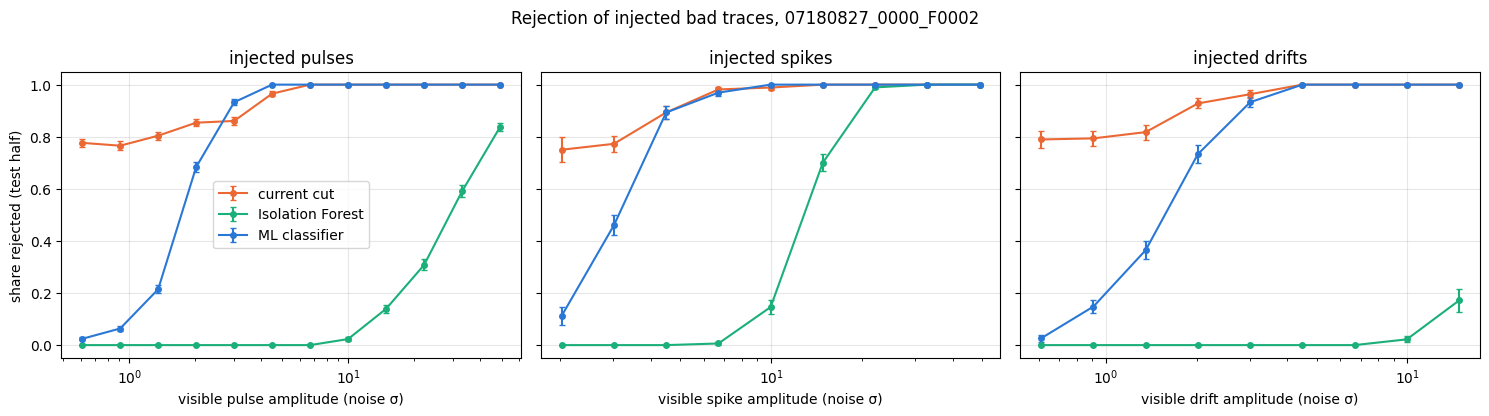

In [12]:
# Injected test set, kept per channel so that the current cut (channel-specific thresholds) can be applied.
inj_test = {}          # key -> (X, kind, amp)
rng_te = np.random.default_rng(2026)
for kind, (lo, hi) in TEST_AMPS.items():
    n_each = 1500
    ev = rng_te.choice(test_pool, n_each, replace=len(test_pool) < n_each)
    a = np.exp(rng_te.uniform(np.log(lo), np.log(hi), n_each))
    traces, hit, vis = inject(ev, kind, a, rng_te)
    Xk, _ = features_of(traces)
    for key in KEYS:
        prev = inj_test.get(key, (np.empty((0, len(FEATURES))), np.empty(0, str), np.empty(0)))
        inj_test[key] = (np.concatenate([prev[0], Xk[key][hit[key]]]),
                         np.concatenate([prev[1], [kind] * hit[key].sum()]),
                         np.concatenate([prev[2], vis[key][hit[key]]]))

METHODS = {
    "current cut": lambda key, X: current_cut(key, X),
    "Isolation Forest": lambda key, X: iso.decision_function(X) > 0,
    "ML classifier": lambda key, X: clf.predict_proba(X)[:, 1] > 0.5,
}

print("clean acceptance on the test half (seed-good traces kept):")
clean_acc = {}
for name, accept in METHODS.items():
    kept = [accept(key, X_all[key][seed_good[key] & ~is_train_event]) for key in KEYS]
    clean_acc[name] = np.concatenate(kept).mean()
    print(f"  {name:<18}{clean_acc[name]:6.1%}")

print()
print("mean of_trig (OF amplitude at the trigger / sigma_A) of the accepted traces, all events; pure noise gives 0:")
print(f"{'channel':<9}" + "".join(f"{n:>22}" for n in ["current cut", "Isolation Forest", "ML classifier", "seed good"]))
for key in KEYS:
    row = ""
    for sel in (CUR_GOOD[key], ISO_GOOD[key], ML_GOOD[key], seed_good[key]):
        v = feats[key]["of_trig"][sel]
        row += f"{v.mean():>14.2f} ± {v.std(ddof=1) / np.sqrt(len(v)):<5.2f}"
    print(f"{str(key):<9}{row}")

AMP_BINS = np.geomspace(0.5, 60, 13)
centres = np.sqrt(AMP_BINS[1:] * AMP_BINS[:-1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, kind in zip(axes, TEST_AMPS):
    for name, accept in METHODS.items():
        rej, amp_all = [], []
        for key in KEYS:
            X, kd, a = inj_test[key]
            m = kd == kind
            rej.append(~accept(key, X[m])); amp_all.append(a[m])
        rej = np.concatenate(rej); amp_all = np.concatenate(amp_all)
        b = np.digitize(amp_all, AMP_BINS) - 1
        eff = np.array([rej[b == i].mean() if np.any(b == i) else np.nan for i in range(len(centres))])
        n_b = np.array([(b == i).sum() for i in range(len(centres))])
        err = np.sqrt(eff * (1 - eff) / np.maximum(n_b, 1))
        ax.errorbar(centres, eff, yerr=err, marker="o", ms=4, lw=1.5, capsize=2, color=COLOUR[name], label=name)
        print(f"{kind:>6} {name:<18} rejected overall {rej.mean():6.1%}")
    ax.set_xscale("log"); ax.set_xlabel(f"visible {kind} amplitude (noise σ)")
    ax.set_title(f"injected {kind}s"); ax.grid(alpha=0.3)
axes[0].set_ylabel("share rejected (test half)"); axes[0].legend()
fig.suptitle(f"Rejection of injected bad traces, {DUMP}", fontsize=12)
fig.tight_layout(); plt.savefig(FIG / f"ml-noise-injection-rejection-{DUMP}.png", dpi=110); plt.show()

ROC AUC, test seeds vs injections >= 3 sigma: ML classifier 0.9974, Isolation Forest 0.9774


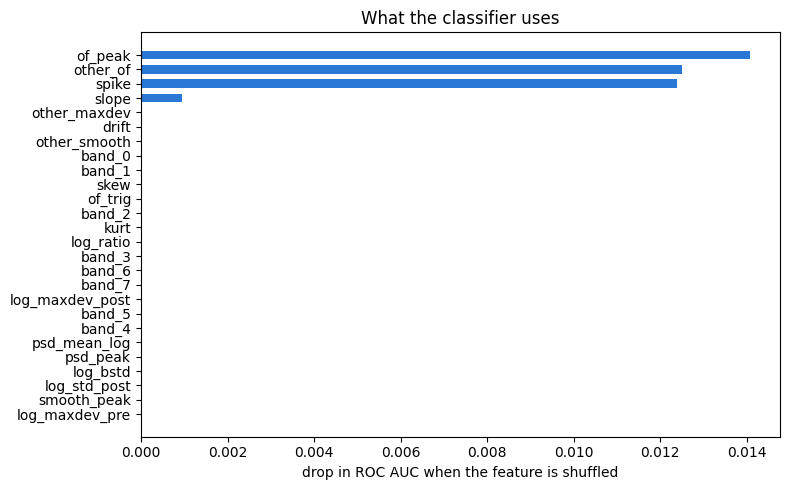

In [13]:
# A single-number summary of how well each method separates the test seeds from the test injections (ROC AUC),
# for the two methods that give a score. The current cut is a yes/no cut and has no curve.
y_eval, s_ml, s_iso = [], [], []
for key in KEYS:
    Xg = X_all[key][seed_good[key] & ~is_train_event]
    Xb = inj_test[key][0][inj_test[key][2] >= 3]           # injections with a visible amplitude of 3 sigma and more
    Xe = np.concatenate([Xg, Xb])
    y_eval.append(np.r_[np.ones(len(Xg)), np.zeros(len(Xb))])
    s_ml.append(clf.predict_proba(Xe)[:, 1]); s_iso.append(iso.decision_function(Xe))
y_eval = np.concatenate(y_eval)
print(f"ROC AUC, test seeds vs injections >= 3 sigma: ML classifier {roc_auc_score(y_eval, np.concatenate(s_ml)):.4f}, "
      f"Isolation Forest {roc_auc_score(y_eval, np.concatenate(s_iso)):.4f}")

# Which features the classifier leans on (permutation importance on a sample of the training set)
from sklearn.inspection import permutation_importance
sample = RNG.choice(len(X_tr), min(6000, len(X_tr)), replace=False)
imp = permutation_importance(clf, X_tr[sample], y_tr[sample], n_repeats=5, random_state=0, scoring="roc_auc")
order = np.argsort(imp.importances_mean)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([FEATURES[i] for i in order][::-1], imp.importances_mean[order][::-1], color="#2a78d6", height=0.6)
ax.set_xlabel("drop in ROC AUC when the feature is shuffled"); ax.set_title("What the classifier uses")
fig.tight_layout(); plt.show()

### 4.1 Where the methods disagree

The interesting traces are the ones the methods disagree on. Below: traces the **ML classifier accepts but the current cut rejects** (good noise the current method throws away, if the classifier is right) and traces the **current cut accepts but the classifier rejects** (contamination the current method lets in, if the classifier is right). Look at them: this is the check by eye that the numbers above cannot give.

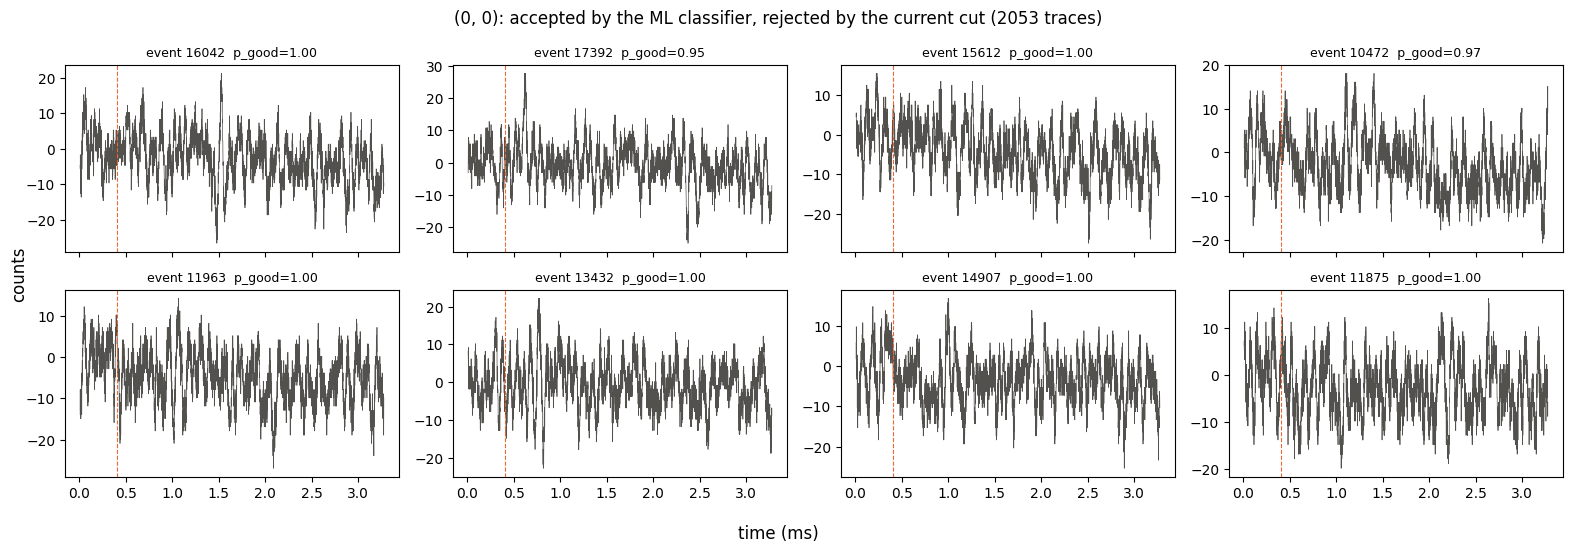

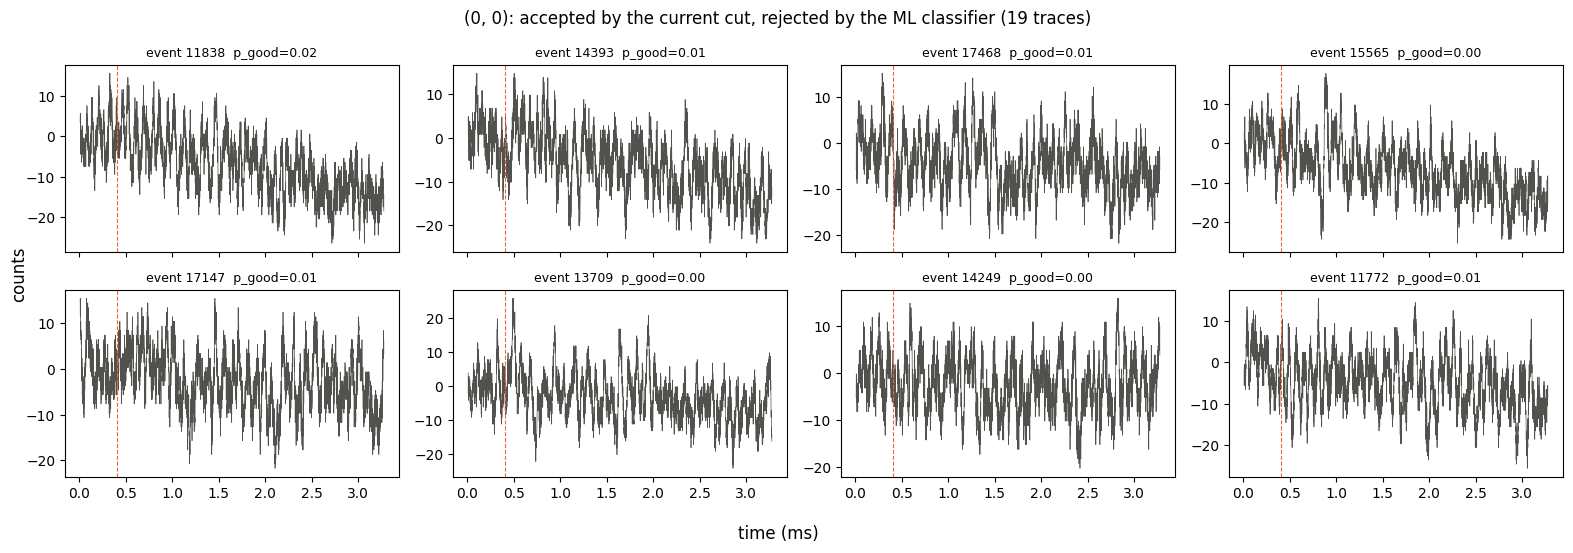

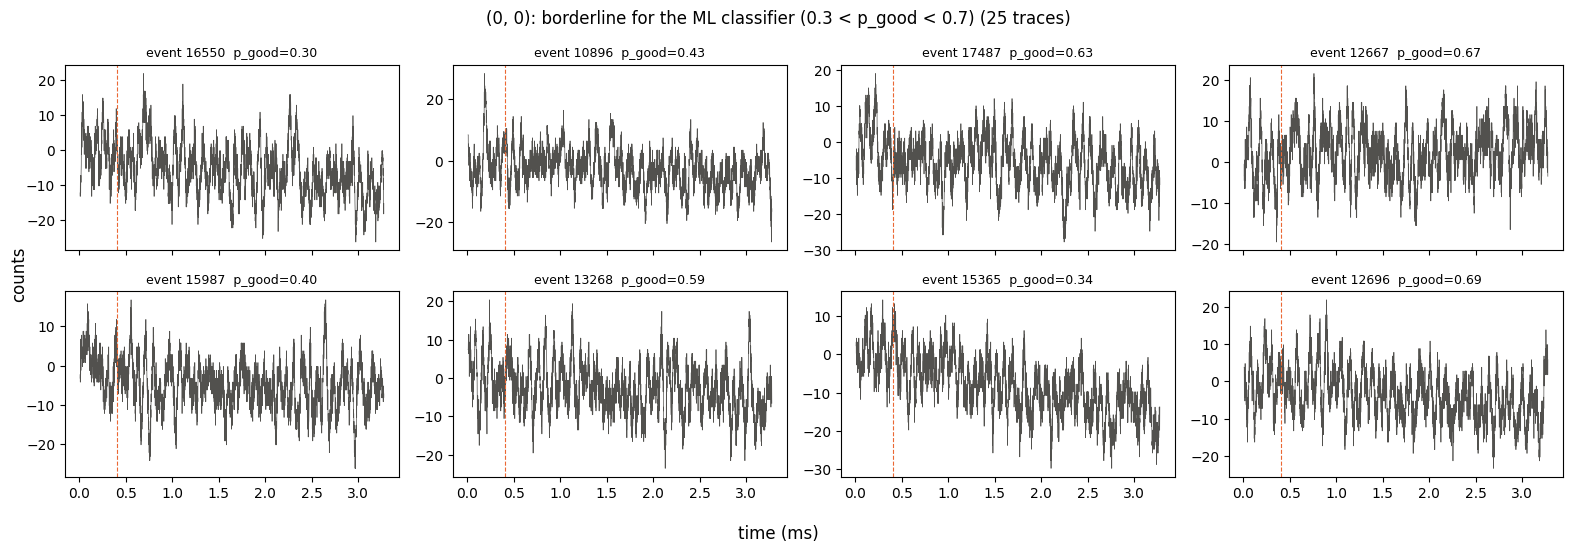

In [14]:
def plot_examples(key, mask, title, n=8):
    rows = np.flatnonzero(mask)
    if len(rows) == 0:
        print(f"{title}: none"); return
    rows = RNG.choice(rows, min(n, len(rows)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(16, 5.5), sharex=True)
    for ax, r in zip(axes.flat, rows):
        ax.plot(t_ms, raw_traces[key][r], lw=0.5, color="#52514e")
        ax.set_title(f"event {event_numbers[r]}  p_good={P_GOOD[key][r]:.2f}", fontsize=9)
        ax.axvline(PRETRIGGER * SAMPLE_PERIOD_S * 1e3, color="#eb6834", lw=0.8, ls="--")
    for ax in axes.flat[len(rows):]:
        ax.axis("off")
    fig.suptitle(f"{key}: {title} ({mask.sum()} traces)", fontsize=12)
    fig.supxlabel("time (ms)"); fig.supylabel("counts")
    fig.tight_layout(); plt.show()

key_show = KEYS[0]
plot_examples(key_show, ML_GOOD[key_show] & ~CUR_GOOD[key_show], "accepted by the ML classifier, rejected by the current cut")
plot_examples(key_show, ~ML_GOOD[key_show] & CUR_GOOD[key_show], "accepted by the current cut, rejected by the ML classifier")
plot_examples(key_show, (P_GOOD[key_show] > 0.3) & (P_GOOD[key_show] < 0.7), "borderline for the ML classifier (0.3 < p_good < 0.7)")

## 5. The noise PSD template

For each channel, the template is the mean one-sided PSD of the accepted traces, with its standard error (std / √N at every bin). The **robust reference** is the bin-by-bin median of the per-trace PSDs of the ML-accepted traces divided by ln 2: for pure Gaussian noise each per-trace PSD bin is exponentially distributed, whose mean is median / ln 2, and a median is hardly moved by a few contaminated traces. A template that sits above the reference at low frequency carries contamination.

**Optimal-filter resolution.** With the pulse shape $s$ (peak 1) and its transform $S_k$, the OF amplitude of a trace $v$ is
$$\hat A = \frac{\sum_k \mathrm{Re}(S_k^* V_k)/J_k}{\sum_k |S_k|^2/J_k},$$
(sum over the positive-frequency bins, DC excluded, no time shift) and for noise with one-sided PSD $J$ its expected spread is $\sigma_A = \sqrt{\frac{N}{4\,\Delta t \sum_k |S_k|^2/J_k}}$ (counts of pulse amplitude). Two numbers per template:

- **predicted** $\sigma_A$, from the template itself;
- **realised** $\sigma_A$: the spread of $\hat A$ over held-out noise traces (true amplitude 0), traces *not* used to build the template. The events are split in two halves at random; the templates come from half A and the realised resolution is measured on the seed-good traces of half B (section 3: within 3 spreads of typical noise in every time-domain, OF and cross-channel feature), so every template is judged on the same traces, picked by neither method's own cut.

A better noise template gives a smaller realised resolution (the filter weights the frequencies better), and a predicted value that agrees with the realised one (the template describes the real noise).

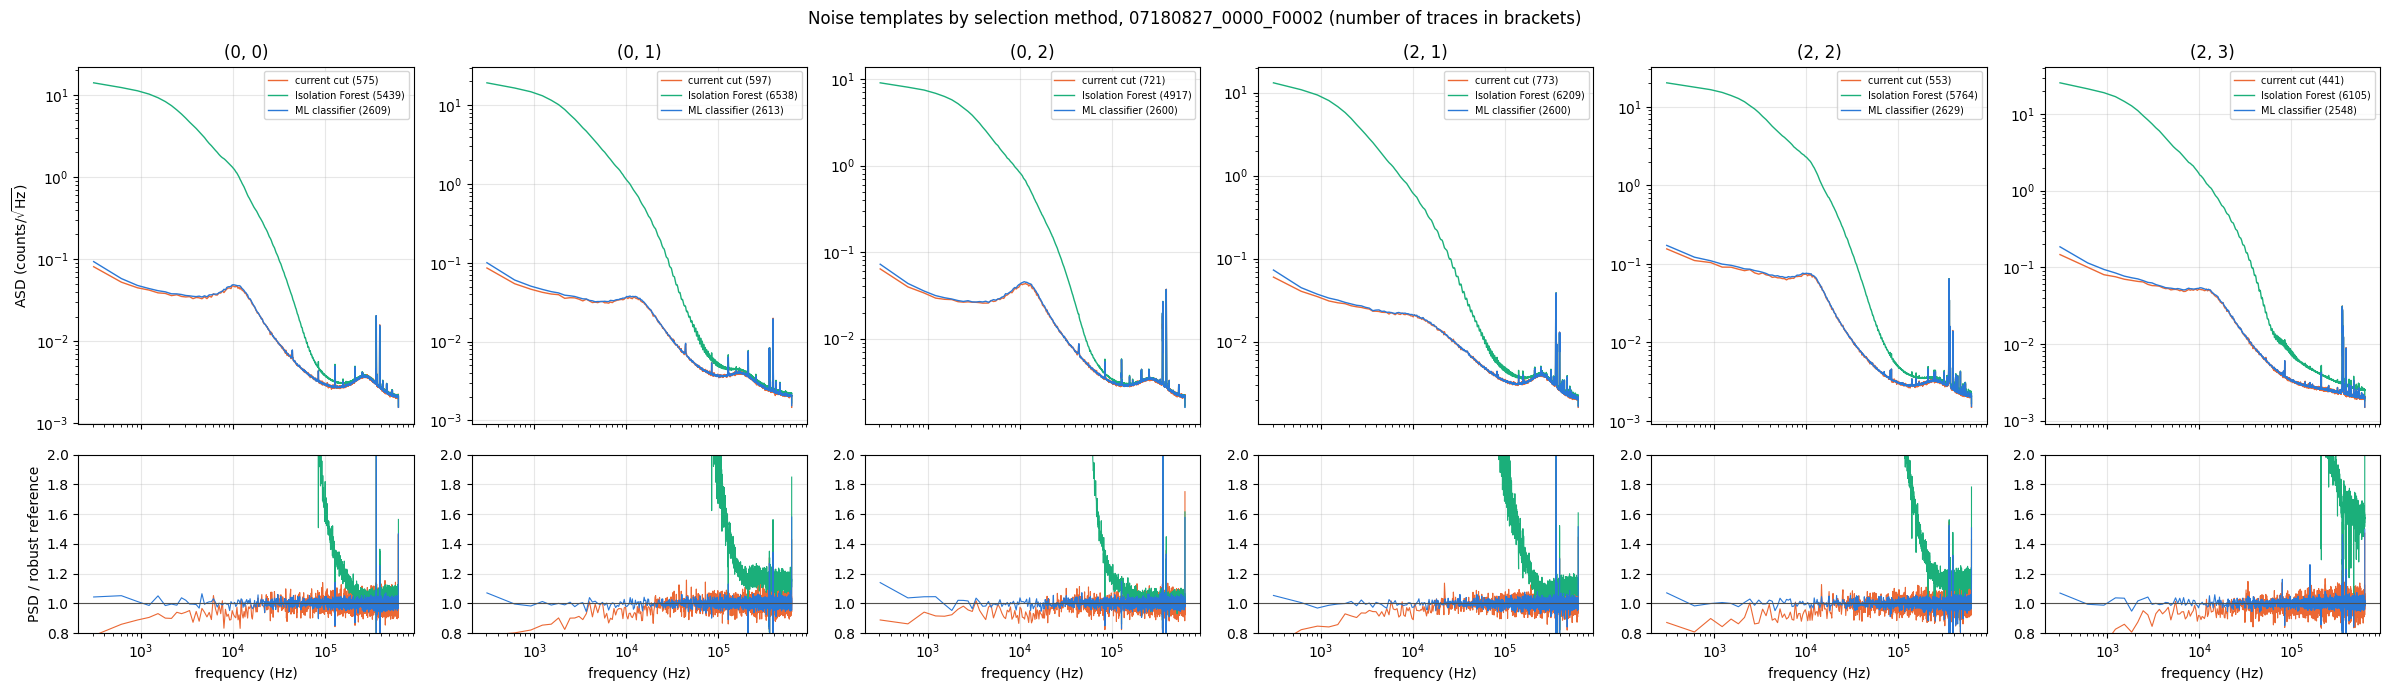

Template / robust reference, mean over each band:
channel  method               0.3-3 kHz    3-30 kHz  30-300 kHz    >300 kHz  median SEM/mean
(0, 0)   current cut              0.858       0.940       0.995       0.961            0.041
(0, 0)   Isolation Forest     37446.749    2267.305      19.535       0.992            0.014
(0, 0)   ML classifier            1.026       1.001       1.000       0.959            0.020
(0, 1)   current cut              0.825       0.945       0.995       0.953            0.041
(0, 1)   Isolation Forest     56353.920    3098.508       9.855       1.054            0.014
(0, 1)   ML classifier            1.022       0.997       0.997       0.953            0.020
(0, 2)   current cut              0.910       0.931       0.995       0.905            0.037
(0, 2)   Isolation Forest     31003.679    1302.636       6.692       0.915            0.014
(0, 2)   ML classifier            1.064       0.996       1.000       0.906            0.020
(2, 1)   current cut

In [15]:
def psd_of_rows(key, rows, chunk=1000):
    x = raw_traces[key]
    return np.concatenate([one_sided_psd(x[rows[i:i + chunk]]) for i in range(0, len(rows), chunk)]) if len(rows) else np.empty((0, len(FREQS)))


SELECTIONS = {"current cut": CUR_GOOD, "Isolation Forest": ISO_GOOD, "ML classifier": ML_GOOD}
PSD_GOOD = {key: psd_of_rows(key, np.flatnonzero(ML_GOOD[key])) for key in KEYS}   # per-trace PSDs, reused below
TEMPLATE = {}
for key in KEYS:
    TEMPLATE[key] = {}
    for name, sel in SELECTIONS.items():
        p = PSD_GOOD[key] if name == "ML classifier" else psd_of_rows(key, np.flatnonzero(sel[key]))
        TEMPLATE[key][name] = (p.mean(axis=0), p.std(axis=0, ddof=1) / np.sqrt(len(p)), len(p))
    TEMPLATE[key]["robust reference"] = (np.median(PSD_GOOD[key], axis=0) / np.log(2), None, len(PSD_GOOD[key]))

fig, axes = plt.subplots(2, len(KEYS), figsize=(4 * len(KEYS), 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for j, key in enumerate(KEYS):
    ref = TEMPLATE[key]["robust reference"][0]
    for name in SELECTIONS:
        mean, sem, n = TEMPLATE[key][name]
        axes[0, j].loglog(FREQS[1:], np.sqrt(mean[1:]), lw=1, color=COLOUR[name], label=f"{name} ({n})")
        r = mean[1:] / ref[1:]
        axes[1, j].semilogx(FREQS[1:], r, lw=0.8, color=COLOUR[name])
    axes[0, j].set_title(str(key)); axes[0, j].legend(fontsize=7); axes[0, j].grid(alpha=0.3, which="major")
    axes[1, j].axhline(1, color="#52514e", lw=0.8); axes[1, j].set_ylim(0.8, 2.0); axes[1, j].grid(alpha=0.3)
    axes[1, j].set_xlabel("frequency (Hz)")
axes[0, 0].set_ylabel("ASD (counts/$\\sqrt{\\mathrm{Hz}}$)"); axes[1, 0].set_ylabel("PSD / robust reference")
fig.suptitle(f"Noise templates by selection method, {DUMP} (number of traces in brackets)", fontsize=12)
fig.tight_layout(); plt.savefig(FIG / f"ml-noise-templates-{DUMP}.png", dpi=110); plt.show()

print("Template / robust reference, mean over each band:")
show_bands = [("0.3-3 kHz", 300, 3e3), ("3-30 kHz", 3e3, 3e4), ("30-300 kHz", 3e4, 3e5), (">300 kHz", 3e5, np.inf)]
print(f"{'channel':<9}{'method':<18}" + "".join(f"{b[0]:>12}" for b in show_bands) + f"{'median SEM/mean':>17}")
for key in KEYS:
    ref = TEMPLATE[key]["robust reference"][0]
    for name in SELECTIONS:
        mean, sem, n = TEMPLATE[key][name]
        vals = [mean[(FREQS >= lo) & (FREQS < hi)].mean() / ref[(FREQS >= lo) & (FREQS < hi)].mean() for _, lo, hi in show_bands]
        print(f"{str(key):<9}{name:<18}" + "".join(f"{v:>12.3f}" for v in vals) + f"{np.median(sem[1:] / mean[1:]):>17.3f}")

In [16]:
def of_weights(key, J):
    S = np.fft.rfft(PULSE[key])
    w = np.conj(S[KBINS]) / J[KBINS]
    norm = np.sum(np.abs(S[KBINS]) ** 2 / J[KBINS])
    sigma_pred = np.sqrt(N_SAMP / (4 * SAMPLE_PERIOD_S * norm))
    return w, norm, sigma_pred


def of_amplitudes(key, rows, J, chunk=2000):
    w, norm, _ = of_weights(key, J)
    x = raw_traces[key]
    out = []
    for i in range(0, len(rows), chunk):
        V = np.fft.rfft(x[rows[i:i + chunk]], axis=1)[:, KBINS]
        out.append(np.real(V @ w) / norm)
    return np.concatenate(out)


half_A = RNG.random(n_events) < 0.5
print(f"{'channel':<9}{'method':<18}{'traces (A)':>11}{'predicted':>11}{'realised (B)':>14}{'realised/pred':>15}")
OF_RESULT = {}
for key in KEYS:
    eval_rows = np.flatnonzero(~half_A & seed_good[key])
    for name, sel in SELECTIONS.items():
        rows_A = np.flatnonzero(half_A & sel[key])
        J = psd_of_rows(key, rows_A).mean(axis=0)
        _, _, pred = of_weights(key, J)
        real = of_amplitudes(key, eval_rows, J).std(ddof=1)
        OF_RESULT[(key, name)] = (len(rows_A), pred, real)
        print(f"{str(key):<9}{name:<18}{len(rows_A):>11}{pred:>11.3f}{real:>14.3f}{real / pred:>15.3f}")
    print(f"{'':<9}(realised on the {len(eval_rows)} seed-good traces of half B)")

# A check of the OF itself: a pulse of known amplitude injected into held-out noise comes back with that amplitude.
key = KEYS[0]
rows = np.flatnonzero(~half_A & ML_GOOD[key])[:300]
J = TEMPLATE[key]["ML classifier"][0]
A_noise = of_amplitudes(key, rows, J)
saved = raw_traces[key][rows].copy()
raw_traces[key][rows] += 20 * PULSE[key]
A_hat = of_amplitudes(key, rows, J)
raw_traces[key][rows] = saved
print(f"OF check on {key} ({len(rows)} accepted traces of half B): noise alone {A_noise.mean():.2f} +- {A_noise.std(ddof=1):.2f}, "
      f"with an injected amplitude of 20: {A_hat.mean():.2f}; difference {np.mean(A_hat - A_noise):.3f} (should be 20)")

channel  method             traces (A)  predicted  realised (B)  realised/pred


(0, 0)   current cut               271      3.886         4.019          1.034


(0, 0)   Isolation Forest         2705     68.846       157.240          2.284


(0, 0)   ML classifier            1298      4.142         4.035          0.974
         (realised on the 1236 seed-good traces of half B)


(0, 1)   current cut               295      3.529         3.688          1.045


...

(2, 2)   current cut               250      7.826         9.143          1.168


(2, 2)   Isolation Forest         2879     86.741       291.799          3.364


(2, 2)   ML classifier            1303      8.352         9.489          1.136
         (realised on the 1229 seed-good traces of half B)
(2, 3)   current cut               210      5.628         6.014          1.069


(2, 3)   Isolation Forest         3053    103.395       241.299          2.334


(2, 3)   ML classifier            1264      6.067         6.133          1.011
         (realised on the 1195 seed-good traces of half B)
OF check on (0, 0) (300 accepted traces of half B): noise alone 2.30 +- 3.85, with an injected amplitude of 20: 22.30; difference 20.000 (should be 20)


## 6. Local noise templates

One template per dump assumes the noise does not change during the dump. Two ways to test it:

1. **Blocks**: the dump is cut into consecutive blocks of events, and a template is made from the accepted traces of each block. For each block and each of 24 log-spaced frequency bands, the difference from the dump-wide template is divided by its standard error; if the noise is the same everywhere, these *pulls* scatter with a spread of 1, and $\chi^2$ per band is about 1.
2. **Rolling template**: every accepted trace gets its own template, the mean PSD of the $K$ accepted traces nearest to it in time (itself excluded). Its realised OF resolution is compared with that of the dump-wide template built the same way (all accepted traces but itself). If the noise changes during the dump, the rolling template is better matched and gives a smaller realised resolution.

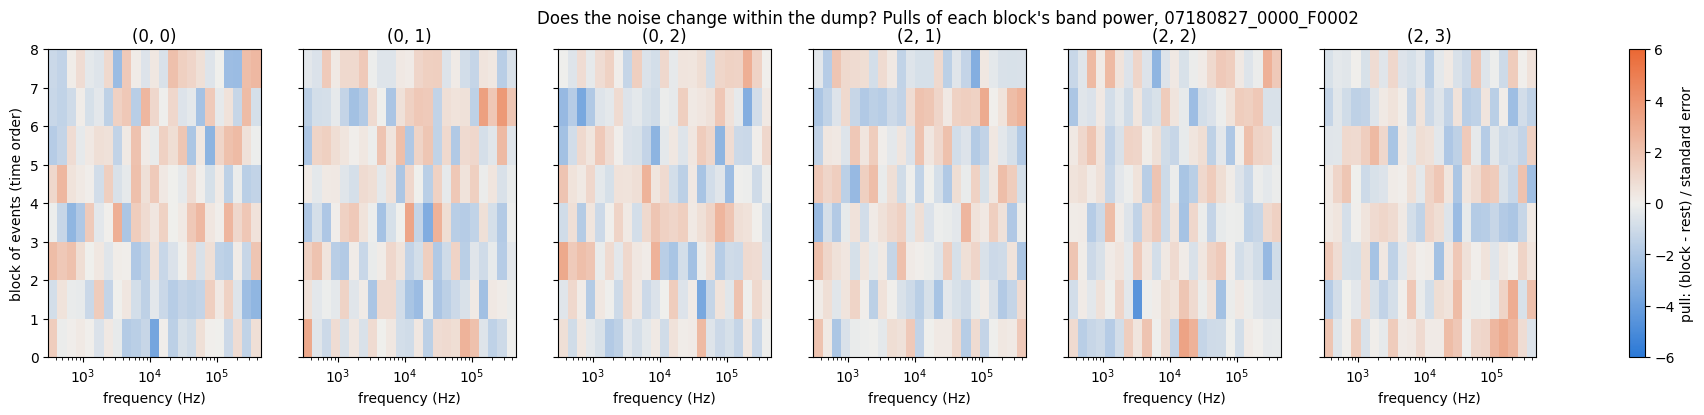

channel    chi2/dof all blocks  largest |pull|  worst band (Hz)              traces per block
(0, 0)                    1.71             3.7            16520[314, 323, 317, 326, 343, 321, 373, 292]
(0, 1)                    1.69             3.8           393111[310, 317, 317, 324, 351, 319, 378, 297]
(0, 2)                    1.51             3.6            58584[309, 317, 319, 322, 344, 317, 378, 294]
(2, 1)                    1.41             3.2           110285[306, 327, 315, 321, 345, 315, 379, 292]
(2, 2)                    1.38             4.6             4589[313, 325, 316, 327, 351, 322, 380, 295]
(2, 3)                    1.34             3.0           208180[307, 319, 308, 319, 336, 311, 369, 279]


In [17]:
N_BLOCKS = 8
block_edges = np.linspace(0, n_events, N_BLOCKS + 1).astype(int)
block_of_event = np.searchsorted(block_edges, np.arange(n_events), side="right") - 1
COARSE_EDGES = np.geomspace(FREQS[1], FREQS[-1], 25)
coarse_bins = [(FREQS >= lo) & (FREQS < hi) for lo, hi in zip(COARSE_EDGES[:-1], COARSE_EDGES[1:])]
coarse_bins = [b for b in coarse_bins if b.sum() > 0]
coarse_f = np.array([FREQS[b].mean() for b in coarse_bins])

LOCAL = {}            # key -> (block templates (blocks, bins), block sems, counts)
PULLS = {}
for key in KEYS:
    rows_good = np.flatnonzero(ML_GOOD[key])
    blk = block_of_event[rows_good]
    psd = PSD_GOOD[key]
    tmpl = np.array([psd[blk == b].mean(axis=0) for b in range(N_BLOCKS)])
    sems = np.array([psd[blk == b].std(axis=0, ddof=1) / np.sqrt((blk == b).sum()) for b in range(N_BLOCKS)])
    counts = np.array([(blk == b).sum() for b in range(N_BLOCKS)])
    LOCAL[key] = (tmpl, sems, counts)
    # pulls per block and coarse band, against the dump-wide mean of the *other* blocks (independent)
    pulls = np.zeros((N_BLOCKS, len(coarse_bins)))
    for b in range(N_BLOCKS):
        p_in = psd[blk == b]; p_out = psd[blk != b]
        for i, cb in enumerate(coarse_bins):
            a = p_in[:, cb].mean(axis=1); c = p_out[:, cb].mean(axis=1)       # per-trace band power
            pulls[b, i] = (a.mean() - c.mean()) / np.sqrt(a.var(ddof=1) / len(a) + c.var(ddof=1) / len(c))
    PULLS[key] = pulls

fig, axes = plt.subplots(1, len(KEYS), figsize=(4 * len(KEYS), 4), sharey=True)
for ax, key in zip(np.atleast_1d(axes), KEYS):
    im = ax.pcolormesh(COARSE_EDGES[:len(coarse_bins) + 1], np.arange(N_BLOCKS + 1), PULLS[key],
                       cmap=DIVERGING, vmin=-6, vmax=6, shading="flat")
    ax.set_xscale("log"); ax.set_xlabel("frequency (Hz)"); ax.set_title(str(key))
np.atleast_1d(axes)[0].set_ylabel("block of events (time order)")
fig.colorbar(im, ax=axes, label="pull: (block - rest) / standard error")
fig.suptitle(f"Does the noise change within the dump? Pulls of each block's band power, {DUMP}", fontsize=12)
plt.savefig(FIG / f"ml-noise-local-pulls-{DUMP}.png", dpi=110, bbox_inches="tight"); plt.show()

print(f"{'channel':<9}{'chi2/dof all blocks':>21}{'largest |pull|':>16}{'worst band (Hz)':>17}{'traces per block':>30}")
for key in KEYS:
    p = PULLS[key]
    b, i = np.unravel_index(np.argmax(np.abs(p)), p.shape)
    print(f"{str(key):<9}{(p ** 2).mean():>21.2f}{np.abs(p).max():>16.1f}{coarse_f[i]:>17.0f}{str(LOCAL[key][2].tolist()):>30}")

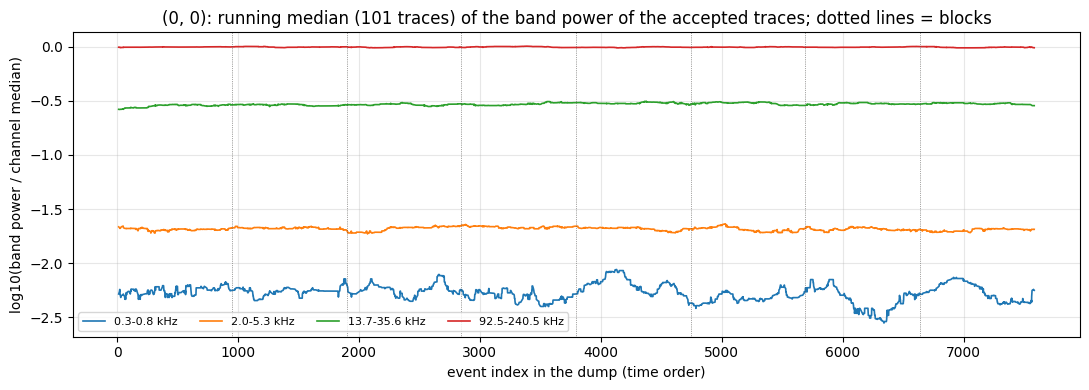

In [18]:
# Band power against time: a running median over the accepted traces, one curve per band, for one channel.
key = KEYS[0]
rows_good = np.flatnonzero(ML_GOOD[key])
fig, ax = plt.subplots(figsize=(11, 4))
for k, (lo, hi) in enumerate(zip(BAND_EDGES[:-1], BAND_EDGES[1:])):
    if k % 2:
        continue
    v = feats[key][f"band_{k}"][rows_good]
    w = 101
    run = np.array([np.median(v[max(0, i - w // 2): i + w // 2 + 1]) for i in range(len(v))])
    ax.plot(rows_good, run, lw=1.2, label=f"{lo / 1e3:.1f}-{hi / 1e3:.1f} kHz")
for e in block_edges[1:-1]:
    ax.axvline(e, color="#52514e", lw=0.5, ls=":")
ax.set_xlabel("event index in the dump (time order)"); ax.set_ylabel("log10(band power / channel median)")
ax.set_title(f"{key}: running median (101 traces) of the band power of the accepted traces; dotted lines = blocks")
ax.legend(fontsize=8, ncol=4); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

In [19]:
# Rolling (local) template versus dump-wide template, both leave-one-out, judged by the realised OF resolution.
K_VALUES = [100, 300, 1000]


def of_on_own_template(key, psd_rows, J_rows, rows):
    # OF amplitude of each trace with its own template J_rows[i] (vectorised over traces).
    S = np.fft.rfft(PULSE[key])[KBINS]
    V = np.fft.rfft(raw_traces[key][rows], axis=1)[:, KBINS]
    J = J_rows[:, KBINS]
    num = np.real(np.conj(S) * V / J).sum(axis=1)
    norm = (np.abs(S) ** 2 / J).sum(axis=1)
    return num / norm, np.sqrt(N_SAMP / (4 * SAMPLE_PERIOD_S * norm))


print(f"{'channel':<9}{'template':<22}{'realised':>10}{'mean predicted':>16}")
ROLLING = {}
for key in KEYS:
    rows_good = np.flatnonzero(ML_GOOD[key])
    psd = PSD_GOOD[key].astype(np.float64)
    n = len(psd)
    total = psd.sum(axis=0)
    J_glob = (total[None, :] - psd) / (n - 1)
    res = {}
    A, pred = [], []
    for i0 in range(0, n, 1000):
        a, p = of_on_own_template(key, psd[i0:i0 + 1000], J_glob[i0:i0 + 1000], rows_good[i0:i0 + 1000])
        A.append(a); pred.append(p)
    res["dump-wide (LOO)"] = (np.concatenate(A).std(ddof=1), np.concatenate(pred).mean())
    del J_glob
    c = np.vstack([np.zeros(psd.shape[1]), np.cumsum(psd, axis=0)])
    for K in K_VALUES:
        A, pred = [], []
        for i0 in range(0, n, 1000):
            i = np.arange(i0, min(i0 + 1000, n))
            lo = np.clip(i - K // 2, 0, n - K - 1); hi = lo + K + 1           # K neighbours + the trace itself
            J = (c[hi] - c[lo] - psd[i]) / K
            a, p = of_on_own_template(key, None, J, rows_good[i])
            A.append(a); pred.append(p)
        res[f"rolling K={K}"] = (np.concatenate(A).std(ddof=1), np.concatenate(pred).mean())
    ROLLING[key] = res
    for name, (real, pr) in res.items():
        print(f"{str(key):<9}{name:<22}{real:>10.4f}{pr:>16.4f}")

channel  template                realised  mean predicted


(0, 0)   dump-wide (LOO)           4.1040          4.1394
(0, 0)   rolling K=100             4.1230          4.1140
(0, 0)   rolling K=300             4.1139          4.1324
(0, 0)   rolling K=1000            4.1060          4.1426


(0, 1)   dump-wide (LOO)           3.6826          3.7766
(0, 1)   rolling K=100             3.7090          3.7535
(0, 1)   rolling K=300             3.6853          3.7696
(0, 1)   rolling K=1000            3.6837          3.7760


(0, 2)   dump-wide (LOO)           3.0054          3.1539
(0, 2)   rolling K=100             3.0182          3.1325
(0, 2)   rolling K=300             3.0070          3.1465
(0, 2)   rolling K=1000            3.0064          3.1550


(2, 1)   dump-wide (LOO)           2.4141          2.5508
(2, 1)   rolling K=100             2.4202          2.5351
(2, 1)   rolling K=300             2.4113          2.5465
(2, 1)   rolling K=1000            2.4154          2.5502


(2, 2)   dump-wide (LOO)          10.0202          8.3602
(2, 2)   rolling K=100            10.0536          8.3057
(2, 2)   rolling K=300            10.0357          8.3497
(2, 2)   rolling K=1000           10.0227          8.3592


(2, 3)   dump-wide (LOO)           6.4833          6.0786
(2, 3)   rolling K=100             6.5214          6.0395
(2, 3)   rolling K=300             6.4922          6.0652
(2, 3)   rolling K=1000            6.4850          6.0766


## 7. Save the templates

One HDF5 file next to this notebook, `noise-templates-ml-<dump>.h5`, readable by an optimal filter without re-running anything:

| where | what |
|---|---|
| file attributes | dump, sample period (and that it is assumed), conventions, units, settings |
| `/frequency_hz` | frequency bins (Hz) |
| `/event_numbers`, `/block_edges` | the dump's events in order; the event-index edges of the local blocks |
| `/channels/det<d>_ch<c>/psd_ml`, `psd_ml_sem` | the ML template and its standard error |
| `.../psd_current`, `psd_current_sem` | the current-cut template, for comparison |
| `.../psd_local`, `psd_local_sem`, `local_counts` | one template per block |
| `.../pulse_shape` | the averaged pulse shape (peak 1) |
| `.../p_good` | the classifier's $p_\mathrm{good}$ for every event |

In [20]:
OUT = Path(f"noise-templates-ml-{DUMP}.h5")
with h5py.File(OUT, "w") as f:
    f.attrs["dump"] = DUMP
    f.attrs["sample_period_s"] = SAMPLE_PERIOD_S
    f.attrs["sample_period_note"] = "ASSUMED 0.8 us (as Fourier Transform Analysis.ipynb); not confirmed for this series"
    f.attrs["psd_convention"] = "one-sided: S = (2 dt / N) |X_k|^2, no factor 2 at DC and Nyquist; pretrigger-mean subtracted (500 samples), 10 glitch samples dropped"
    f.attrs["units"] = "psd: counts^2/Hz"
    f.attrs["samples_per_trace"] = N_SAMP
    f.attrs["classifier"] = "HistGradientBoostingClassifier on time/frequency/cross-channel features, trained on seeds + injected pulses/spikes/drifts; good = p_good > 0.5"
    f.attrs["current_cut"] = "cuts.excursion_band [0.5, 0.7) on 500-sample pretrigger & cuts.quiet_baseline(percentile=25), per channel"
    f.create_dataset("frequency_hz", data=FREQS)
    f.create_dataset("event_numbers", data=event_numbers)
    f.create_dataset("block_edges", data=block_edges)
    g_all = f.create_group("channels")
    for key in KEYS:
        g = g_all.create_group(f"det{key[0]}_ch{key[1]}")
        g.attrs.update(detector=key[0], channel=key[1], noise_sigma_counts=NOISE_SIGMA[key])
        for label, name in (("ml", "ML classifier"), ("current", "current cut")):
            mean, sem, n = TEMPLATE[key][name]
            g.create_dataset(f"psd_{label}", data=mean); g.create_dataset(f"psd_{label}_sem", data=sem)
            g.attrs[f"n_{label}"] = n
        g.create_dataset("psd_local", data=LOCAL[key][0]); g.create_dataset("psd_local_sem", data=LOCAL[key][1])
        g.create_dataset("local_counts", data=LOCAL[key][2])
        g.create_dataset("pulse_shape", data=PULSE[key])
        g.create_dataset("p_good", data=P_GOOD[key].astype(np.float32))

with h5py.File(OUT, "r") as f:
    for key in KEYS:
        assert np.allclose(f["channels"][f"det{key[0]}_ch{key[1]}"]["psd_ml"][:], TEMPLATE[key]["ML classifier"][0])
    print(f"{OUT} written and read back: {len(f['channels'])} channels, {len(f['frequency_hz'])} bins, {OUT.stat().st_size / 1e6:.1f} MB")

noise-templates-ml-07180827_0000_F0002.h5 written and read back: 6 channels, 2044 bins, 1.9 MB


## 8. What the results say, and what to do next

**What the run of 2026-10-26 showed** (dump `07180827_0000_F0002`, sample period assumed 0.8 µs; re-read the outputs if you change anything, since the numbers move with the random seeds and settings):

- **Use of the data.** The classifier accepts about 2600 traces per channel, against 440 to 770 for the current cut (about 4 times as many), and keeps 99.8% of the clean held-out traces against 24%. The template's statistical error drops from about 4% to 2% per bin.
- **Classification.** Injected pulses with a visible amplitude of 3 noise σ are rejected 93% of the time and from about 4.5 σ always; spikes and drifts similarly. ROC AUC 0.997 against 0.977 for the Isolation Forest. The Isolation Forest is unusable on its own here: half the dump is pulses, so to it pulses are not anomalies, and its template is wrong by orders of magnitude at low frequency.
- **Template quality.** The ML template agrees with the robust (median) reference within 2 to 6% at 0.3 to 3 kHz. The current cut's template is **10 to 25% low** there: its quiet-baseline percentile prefers traces that happen to have little low-frequency noise, a selection bias that the classifier avoids. With the ML template the OF's predicted resolution agrees with the realised one on held-out traces (ratio 0.90 to 1.14). Both give about the same realised resolution, so in this dump the gain is mainly a template that is **right** (unbiased, a believable predicted resolution) rather than a smaller resolution.
- **Remaining contamination.** In every selection, current cut included, the mean OF amplitude at the trigger is 0.3 to 0.8 σ_A, not 0: this dump has no random triggers, and small triggering pulses below the noise cannot be told from noise one trace at a time. Random triggers (or a pretrigger-only template) are the real cure.
- **Local templates.** The block pulls show no structure in time (χ²/dof 1.3 to 1.7, largest pull below 5, and no block or band stands out), and rolling templates of 100 to 1000 traces give the same realised OF resolution as the dump-wide one (no better within 1%). **For this 62-second dump, one template per dump is enough**; the local machinery is in place for longer dumps or other series, where it may not be.

Questions to answer from the outputs:

- **Use of the data.** How many traces per channel does the classifier accept compared with the current cut (section 3.3)? How much smaller is the template's standard error (section 5, `median SEM/mean`)?
- **Classification quality.** Clean acceptance and the rejection curves (section 4): from what pulse amplitude (in noise σ) is each method above 90% rejection? Are the disagreements of 4.1 really good noise or really contaminated, by eye?
- **Template quality.** Does the current-cut template sit above the robust reference at low frequency (contamination)? Which template gives the smallest *realised* OF resolution on held-out traces, and is it close to its *predicted* one?
- **Local templates.** Are the block pulls consistent with 1 (no change in time), or are some bands or blocks far out? Does the rolling template beat the dump-wide one in realised resolution? If not, a single template per dump is enough for this dump; if so, by how much, and at which $K$?

Next steps:

- Find the true sample period and channel map of series `07180827` (and rerun with them).
- Repeat on other dumps of the series, and on the Run 76 dump `07221203_2025_F0001` (where the random-trigger label exists, so the classifier can be compared with buddy's 101 `clean_randoms`).
- A semi-supervised refinement: hand-label a few hundred of the borderline traces of 4.1, add them to the training set, and see how much the numbers move.
- Use time-shifted OF (a fit of the pulse start) for the realised resolution, as a real analysis would.